# Лабораторная работа № 4. Метрики качества, baselines и стратегии валидации

**Выполнил: Голубенко Никита**

**Цель работы** — сравнить простые прогнозные модели, оценить их качество разными метриками и проверить схемы временной валидации без утечки данных.

В работе используется тот же синтетический почасовой ряд, что и в предыдущей лабораторной. Он содержит линейный тренд, суточную и недельную сезонности, ступенчатое изменение уровня, шум с постепенно меняющейся дисперсией и точечные выбросы.

Поскольку данные почасовые, горизонт прогноза выбран равным **168 часам (одна неделя)**. Backtesting проводится на последних десяти недельных блоках. Expanding window использует всю доступную историю, sliding window — последние четыре недели (672 наблюдения). Оба варианта проверяются на одинаковых тестовых блоках.

## 1. Импорт библиотек и параметры

Для Theta используется `ThetaModel` из `statsmodels`. Все преобразования и оценки внутри backtesting выполняются только на обучающей части соответствующего временного окна.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.forecasting.theta import ThetaModel

SEED = 42
START = "2023-01-01 00:00:00"
N_DAYS = 731  # 2023 и високосный 2024 год
N_POINTS = N_DAYS * 24
FREQ = "h"
DAILY_PERIOD = 24
WEEKLY_PERIOD = 168
HORIZON = WEEKLY_PERIOD             # прогноз на одну неделю
N_SPLITS = 10                       # десять тестовых недель
SLIDING_WINDOW = 4 * WEEKLY_PERIOD  # четыре недельных сезонных периода
OUTPUT_DIR = Path("results_lecture4_baselines")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if N_SPLITS < 2:
    raise ValueError("Для backtesting и калибровки интервалов требуется не менее двух фолдов.")
if HORIZON < 1 or SLIDING_WINDOW < WEEKLY_PERIOD:
    raise ValueError("Проверьте горизонт и размер скользящего окна.")

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 30)
pd.set_option("display.expand_frame_repr", False)
plt.rcParams["figure.figsize"] = (13, 5)

print("pandas:", pd.__version__)
print("Наблюдений:", N_POINTS)
print("Частота:", FREQ)
print("Сезонные периоды:", DAILY_PERIOD, "и", WEEKLY_PERIOD, "часов")
print("Горизонт:", HORIZON, "часов; folds:", N_SPLITS)
print("Sliding window:", SLIDING_WINDOW, "часов")

pandas: 3.0.0
Наблюдений: 17544
Частота: h
Сезонные периоды: 24 и 168 часов
Горизонт: 168 часов; folds: 10
Sliding window: 672 часов


## 2. Генерация временного ряда

Генератор повторяет структуру ряда из ЛР № 3: почасовой индекс, тренд, суточная синусоидальная компонента, недельный эффект по дням недели, ступенчатый сдвиг уровня и 12 выбросов. Фиксированный `SEED` обеспечивает воспроизводимость.

In [2]:
def generate_hourly_multiseasonal_series(
    n_points=N_POINTS,
    start=START,
    seed=SEED,
    daily_period=DAILY_PERIOD,
    weekly_period=WEEKLY_PERIOD,
    noise_start=7.0,
    noise_end=10.0,
    level_shift_start="2024-03-01 00:00:00",
    level_shift=18.0,
    n_outliers=12,
    min_train_points=SLIDING_WINDOW,
    forecast_horizon=HORIZON,
    n_splits=N_SPLITS,
):
    min_required = min_train_points + forecast_horizon * n_splits
    if n_points < max(2 * weekly_period, min_required):
        raise ValueError("Недостаточно наблюдений: требуется минимальное обучающее окно и все тестовые блоки.")
    if daily_period != 24 or weekly_period != 168:
        raise ValueError("Для данной реализации ожидаются периоды 24 и 168 часов.")
    if not 0 <= n_outliers <= n_points - 48:
        raise ValueError("Некорректное число выбросов.")

    rng = np.random.default_rng(seed)
    index = pd.date_range(start=start, periods=n_points, freq=FREQ, name="timestamp")
    t = np.arange(n_points, dtype=float)
    hour = index.hour.to_numpy()
    weekday = index.dayofweek.to_numpy()

    linear_trend = 155.0 + 0.0025 * t
    daily = (
        42.0 * np.sin(2 * np.pi * (hour - 8) / daily_period)
        + 16.0 * np.sin(4 * np.pi * (hour - 8) / daily_period)
    )
    weekday_effect = np.array([14.0, 16.0, 15.0, 12.0, 9.0, -27.0, -31.0])
    weekly = weekday_effect[weekday] + 4.0 * np.sin(2 * np.pi * t / weekly_period)

    noise_scale = np.linspace(noise_start, noise_end, n_points)
    noise = rng.normal(0.0, noise_scale, size=n_points)
    base = linear_trend + daily + weekly + noise
    level_shift_component = np.where(index >= pd.Timestamp(level_shift_start), level_shift, 0.0)
    shifted = base + level_shift_component

    eligible = np.arange(24, n_points - 24)
    outlier_indices = np.sort(rng.choice(eligible, size=n_outliers, replace=False))
    signs = np.array([1.0] * (n_outliers // 2) + [-1.0] * (n_outliers - n_outliers // 2))
    rng.shuffle(signs)
    magnitudes = rng.uniform(150.0, 230.0, size=n_outliers)
    contaminated = shifted.copy()
    for idx, sign, magnitude in zip(outlier_indices, signs, magnitudes):
        contaminated[idx] = max(0.0, contaminated[idx] + sign * magnitude)

    return pd.Series(contaminated, index=index, name="cnt"), outlier_indices

series, outlier_indices = generate_hourly_multiseasonal_series()
print("Период:", series.index.min(), "—", series.index.max())
print("Количество наблюдений:", len(series))
print("Минимум / максимум:", round(series.min(), 3), "/", round(series.max(), 3))
print("Число выбросов:", len(outlier_indices))
display(series.describe().to_frame("Исходный ряд"))

Период: 2023-01-01 00:00:00 — 2024-12-31 23:00:00
Количество наблюдений: 17544
Минимум / максимум: 0.0 / 419.243
Число выбросов: 12


,Исходный ряд
count,17544.000000
mean,185.598317
std,43.912412
min,0.000000
25%,154.280022
50%,185.280684
75%,217.426500
max,419.242526


## 3. Визуальный анализ

Ряд имеет выраженные суточные и недельные колебания, слабый линейный рост и ступенчатый сдвиг уровня с 1 марта 2024 года. Эти особенности важны при выборе baseline: Seasonal Naive повторяет профиль предыдущей недели.

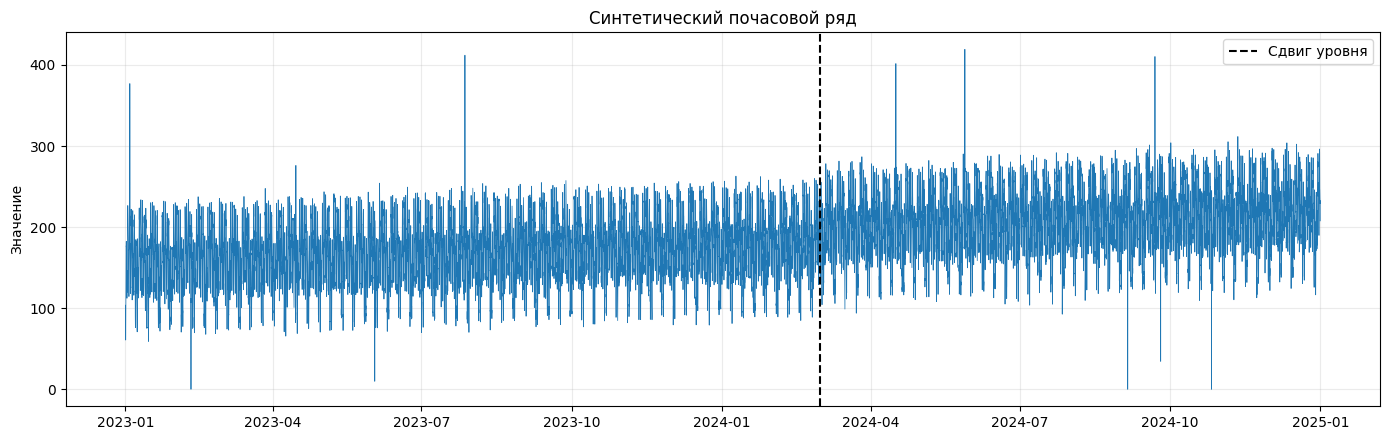

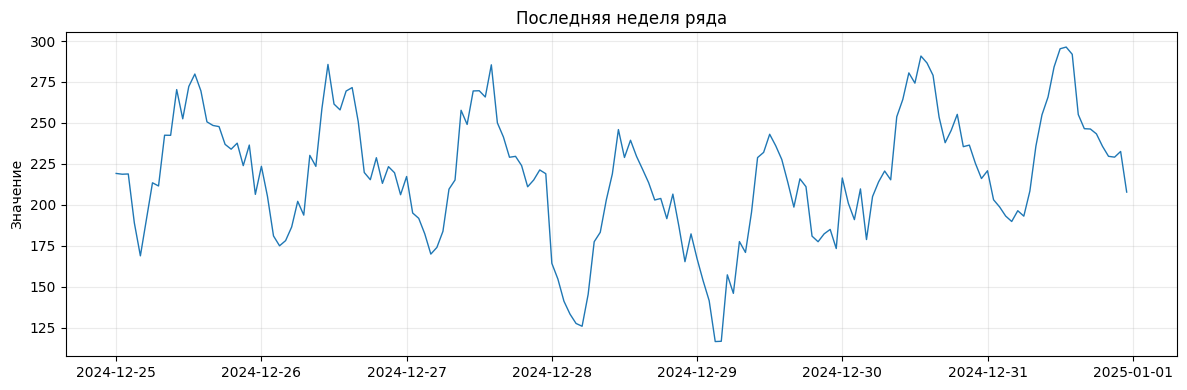

In [3]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(series.index, series.values, linewidth=0.55)
ax.axvline(pd.Timestamp("2024-03-01"), color="black", linestyle="--", label="Сдвиг уровня")
ax.set_title("Синтетический почасовой ряд")
ax.set_ylabel("Значение")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_series.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
last_week = series.iloc[-WEEKLY_PERIOD:]
ax.plot(last_week.index, last_week.values, linewidth=1)
ax.set_title("Последняя неделя ряда")
ax.set_ylabel("Значение")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_last_week.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Baseline-модели

Реализованы пять моделей из лекции:

- **Naive** — последнее наблюдение повторяется на всём горизонте.
- **Seasonal Naive** — повторяется последняя известная неделя (`s = 168`).
- **Mean** — прогноз равен среднему обучающей выборки.
- **Drift** — линейный тренд между первым и последним значениями обучающей выборки продолжается вперёд.
- **Theta** — модель `ThetaModel` с учётом суточного периода (`period = 24`).

Theta учитывает один сезонный период, поэтому здесь используется как baseline с суточной сезонностью, а не как полноценная модель двух сезонностей.

In [4]:
def forecast_naive(train, horizon):
    return np.repeat(float(train.iloc[-1]), horizon)


def forecast_seasonal_naive(train, horizon, season=WEEKLY_PERIOD):
    if len(train) < season:
        raise ValueError(f"Для Seasonal Naive требуется минимум {season} наблюдений.")
    repeats = int(np.ceil(horizon / season))
    return np.tile(train.iloc[-season:].to_numpy(dtype=float), repeats)[:horizon]


def forecast_mean(train, horizon):
    return np.repeat(float(train.mean()), horizon)


def forecast_drift(train, horizon):
    values = train.to_numpy(dtype=float)
    slope = (values[-1] - values[0]) / (len(values) - 1)
    return values[-1] + np.arange(1, horizon + 1) * slope


def forecast_theta(train, horizon):
    model = ThetaModel(train.astype(float), period=DAILY_PERIOD, deseasonalize=True)
    fitted = model.fit()
    forecast = fitted.forecast(horizon)
    values = np.asarray(forecast, dtype=float)
    if len(values) != horizon or not np.isfinite(values).all():
        raise RuntimeError("ThetaModel вернула некорректный прогноз.")
    return values


BASELINES = {
    "Naive": forecast_naive,
    "Seasonal Naive": forecast_seasonal_naive,
    "Mean": forecast_mean,
    "Drift": forecast_drift,
    "Theta": forecast_theta,
}

# Проверка функций на одном обучающем фрагменте.
_demo_train = series.iloc[:SLIDING_WINDOW]
for model_name, model_fn in BASELINES.items():
    pred = model_fn(_demo_train, HORIZON)
    assert len(pred) == HORIZON and np.isfinite(pred).all(), f"Проблема в модели {model_name}"
print("Проверка выполнена: все пять baselines возвращают конечный прогноз длины H.")

Проверка выполнена: все пять baselines возвращают конечный прогноз длины H.


## 5. Метрики качества

Для каждого тестового блока рассчитываются MAE, RMSE, MAPE, sMAPE и MASE. MAPE вычисляется только для фактических значений, отличных от нуля, число использованных точек фиксируется отдельно. Для сезонного ряда MASE нормируется на ошибку Seasonal Naive на обучающей выборке с периодом 168 часов.

В сводной таблице MAE, RMSE, sMAPE и Bias агрегируются с учётом числа точек в фолде, MAPE — pooled-среднее по ненулевым фактам. MASE усредняется по фолдам, поскольку его масштаб рассчитывается отдельно по каждому train.

In [5]:
def calculate_metrics(y_true, y_pred, y_train, season=WEEKLY_PERIOD):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_true - y_pred
    abs_error = np.abs(error)

    mae = float(np.mean(abs_error))
    rmse = float(np.sqrt(np.mean(error ** 2)))

    nonzero = np.abs(y_true) > 1e-8
    mape = float(np.mean(abs_error[nonzero] / np.abs(y_true[nonzero])) * 100) if nonzero.any() else np.nan
    smape_denom = np.abs(y_true) + np.abs(y_pred)
    smape_terms = np.divide(2 * abs_error, smape_denom, out=np.zeros_like(abs_error), where=smape_denom > 1e-8)
    smape = float(np.mean(smape_terms) * 100)

    train_values = np.asarray(y_train, dtype=float)
    if len(train_values) <= season:
        raise ValueError("Для сезонного MASE недостаточно обучающих наблюдений.")
    scale = float(np.mean(np.abs(train_values[season:] - train_values[:-season])))
    mase = mae / scale if scale > 1e-12 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE, %": mape,
        "sMAPE, %": smape,
        "MASE (s=168)": mase,
        "MAPE points": int(nonzero.sum()),
        "Bias (forecast - actual)": float(np.mean(y_pred - y_true)),
    }

## 6. Бэктестинг с расширяющимся и скользящим окном.

Горизонт каждого прогноза равен одной неделе (`H = 168`). Проверяются последние десять недель ряда. Для expanding window обучающая выборка каждый раз включает все наблюдения до начала тестового блока. Для sliding window берутся последние 672 часа перед тестом. Тестовые интервалы одинаковы для обеих схем, поэтому сравнение корректно.

In [6]:
# Все схемы используют одни и те же последние N_SPLITS тестовых блоков.
backtest_start = len(series) - N_SPLITS * HORIZON
if backtest_start < SLIDING_WINDOW:
    raise ValueError("Недостаточно истории для заданного числа фолдов и sliding window.")
fold_starts = list(range(backtest_start, len(series), HORIZON))
if len(fold_starts) != N_SPLITS or fold_starts[-1] + HORIZON != len(series):
    raise RuntimeError("Не удалось построить ожидаемое число тестовых блоков.")

fold_rows = []
forecast_store = {}

for scheme in ["expanding", "sliding"]:
    for fold_id, start in enumerate(fold_starts, start=1):
        if scheme == "expanding":
            train = series.iloc[:start]
        elif scheme == "sliding":
            train = series.iloc[start - SLIDING_WINDOW:start]
        else:
            raise ValueError(f"Неизвестная схема: {scheme}")
        test = series.iloc[start:start + HORIZON]
        if len(test) != HORIZON:
            raise RuntimeError(f"Неверная длина тестового блока в фолде {fold_id}.")

        for model_name, model_fn in BASELINES.items():
            prediction = np.asarray(model_fn(train, HORIZON), dtype=float)
            if len(prediction) != HORIZON or not np.isfinite(prediction).all():
                raise RuntimeError(f"Некорректный прогноз: {scheme}, fold={fold_id}, model={model_name}")

            metrics = calculate_metrics(test.to_numpy(), prediction, train.to_numpy())
            fold_rows.append({
                "Схема": scheme,
                "Fold": fold_id,
                "Начало теста": test.index[0],
                "Конец теста": test.index[-1],
                "Длина train": len(train),
                "Точек теста": len(test),
                "Модель": model_name,
                **metrics,
            })
            forecast_store[(scheme, fold_id, model_name)] = {
                "train": train,
                "test": test,
                "prediction": prediction,
            }

fold_results = pd.DataFrame(fold_rows)
display(fold_results.head(10))
print("Количество проверенных прогнозов:", len(fold_results))

,Схема,Fold,Начало теста,Конец теста,Длина train,Точек теста,Модель,MAE,RMSE,"MAPE, %","sMAPE, %",MASE (s=168),MAPE points,Bias (forecast - actual)
0,expanding,1,2024-10-23,2024-10-29 23:00:00,15864,168,Naive,32.941260,42.382516,16.483217,16.223363,3.359702,167,8.634459
1,expanding,1,2024-10-23,2024-10-29 23:00:00,15864,168,Seasonal Naive,12.632370,21.790685,5.622685,6.827043,1.288384,167,0.867606
2,expanding,1,2024-10-23,2024-10-29 23:00:00,15864,168,Mean,41.441335,51.415960,17.904997,20.711322,4.226631,167,-30.362429
3,expanding,1,2024-10-23,2024-10-29 23:00:00,15864,168,Drift,32.963847,42.500202,16.538734,16.230513,3.362006,167,9.261605
4,expanding,1,2024-10-23,2024-10-29 23:00:00,15864,168,Theta,26.129840,37.673467,12.963468,12.742967,2.665001,167,24.575969
5,expanding,2,2024-10-30,2024-11-05 23:00:00,16032,168,Naive,31.581245,38.641063,16.197660,15.065397,3.211186,168,3.523167
6,expanding,2,2024-10-30,2024-11-05 23:00:00,16032,168,Seasonal Naive,11.989481,20.186927,5.788304,6.362747,1.219092,168,-1.270067
7,expanding,2,2024-10-30,2024-11-05 23:00:00,16032,168,Mean,41.163311,49.611553,18.246728,19.946001,4.185492,168,-31.314327
8,expanding,2,2024-10-30,2024-11-05 23:00:00,16032,168,Drift,31.566529,38.689839,16.236020,15.057530,3.209690,168,4.123494
9,expanding,2,2024-10-30,2024-11-05 23:00:00,16032,168,Theta,23.196056,31.178187,12.430318,11.063042,2.358579,168,21.861183


Количество проверенных прогнозов: 100


## 7. Сводное сравнение baselines

Ошибки MAE, RMSE, MAPE и sMAPE агрегируются по всем 10 тестовым неделям. MASE усредняется по фолдам, поскольку его масштаб рассчитывается отдельно по обучающей выборке каждого фолда. Лучший baseline в каждой схеме определяется по минимальному MASE.

Дополнительно рассчитывается стандартное отклонение MAE по десяти фолдам для каждой модели. Оно характеризует разброс ошибок конкретного baseline на выбранных тестовых блоках. Для сравнения схем ниже также приводится среднее этих стандартных отклонений по пяти моделям.

In [7]:
metric_rows = []
for (scheme, model_name), group in fold_results.groupby(["Схема", "Модель"], sort=False):
    test_counts = group["Точек теста"].to_numpy(dtype=float)
    mape_counts = group["MAPE points"].to_numpy(dtype=float)
    mape_values = group["MAPE, %"].to_numpy(dtype=float)
    valid_mape = np.isfinite(mape_values) & (mape_counts > 0)

    metric_rows.append({
        "Схема": scheme,
        "Модель": model_name,
        # Взвешивание по числу точек делает агрегирование корректным и при разных H по фолдам.
        "MAE": float(np.average(group["MAE"], weights=test_counts)),
        "RMSE": float(np.sqrt(np.average(group["RMSE"].to_numpy() ** 2, weights=test_counts))),
        # MAPE — pooled-среднее по всем ненулевым фактическим значениям.
        "MAPE, %": float(np.average(mape_values[valid_mape], weights=mape_counts[valid_mape])) if valid_mape.any() else np.nan,
        "MAPE points total": int(mape_counts.sum()),
        "sMAPE, %": float(np.average(group["sMAPE, %"], weights=test_counts)),
        # MASE усредняется по фолдам: у каждого фолда собственный train-scale.
        "MASE (s=168)": float(group["MASE (s=168)"].mean()),
        "Bias": float(np.average(group["Bias (forecast - actual)"], weights=test_counts)),
        "Точек теста total": int(test_counts.sum()),
    })

metrics_summary = pd.DataFrame(metric_rows).sort_values(["Схема", "MASE (s=168)"]).reset_index(drop=True)
metrics_display = metrics_summary.copy()
num_cols = metrics_display.select_dtypes(include="number").columns
metrics_display[num_cols] = metrics_display[num_cols].round(4)
display(metrics_display)

best_by_scheme = metrics_summary.loc[
    metrics_summary.groupby("Схема")["MASE (s=168)"].idxmin(),
    ["Схема", "Модель", "MASE (s=168)"]
]
display(best_by_scheme.round(4))

stability_summary = fold_results.groupby(["Схема", "Модель"])["MAE"].agg(
    Средний_MAE="mean", Стандартное_отклонение_MAE="std"
).reset_index()
display(stability_summary.round(4))

,Схема,Модель,MAE,RMSE,"MAPE, %",MAPE points total,"sMAPE, %",MASE (s=168),Bias,Точек теста total
0,expanding,Seasonal Naive,11.3275,15.5522,5.3767,1679,5.5652,1.1460,-0.4359,1680
1,expanding,Theta,21.4055,29.4059,11.2320,1679,10.2299,2.1660,17.5839,1680
2,expanding,Drift,33.1922,40.7239,16.5217,1679,15.6740,3.3575,1.6869,1680
3,expanding,Naive,33.1996,40.7006,16.4835,1679,15.6807,3.3582,1.1074,1680
4,expanding,Mean,41.6564,50.9114,18.1604,1679,20.0312,4.2137,-32.4309,1680
5,sliding,Seasonal Naive,11.3275,15.5522,5.3767,1679,5.5652,1.0059,-0.4359,1680
6,sliding,Theta,21.9198,29.8534,11.3740,1679,10.3828,1.9456,17.8130,1680
7,sliding,Mean,32.0813,39.2601,15.7923,1679,15.1692,2.8432,-1.2104,1680
8,sliding,Naive,33.1996,40.7006,16.4835,1679,15.6807,2.9428,1.1074,1680
9,sliding,Drift,33.4144,41.0579,16.6746,1679,15.7730,2.9617,2.3978,1680


,Схема,Модель,MASE (s=168)
0,expanding,Seasonal Naive,1.1460
5,sliding,Seasonal Naive,1.0059


,Схема,Модель,Средний_MAE,Стандартное_отклонение_MAE
0,expanding,Drift,33.1922,1.3190
1,expanding,Mean,41.6564,0.6466
2,expanding,Naive,33.1996,1.3453
3,expanding,Seasonal Naive,11.3275,0.8284
4,expanding,Theta,21.4055,2.4319
5,sliding,Drift,33.4144,1.4767
6,sliding,Mean,32.0813,1.0008
7,sliding,Naive,33.1996,1.3453
8,sliding,Seasonal Naive,11.3275,0.8284
9,sliding,Theta,21.9198,2.4497


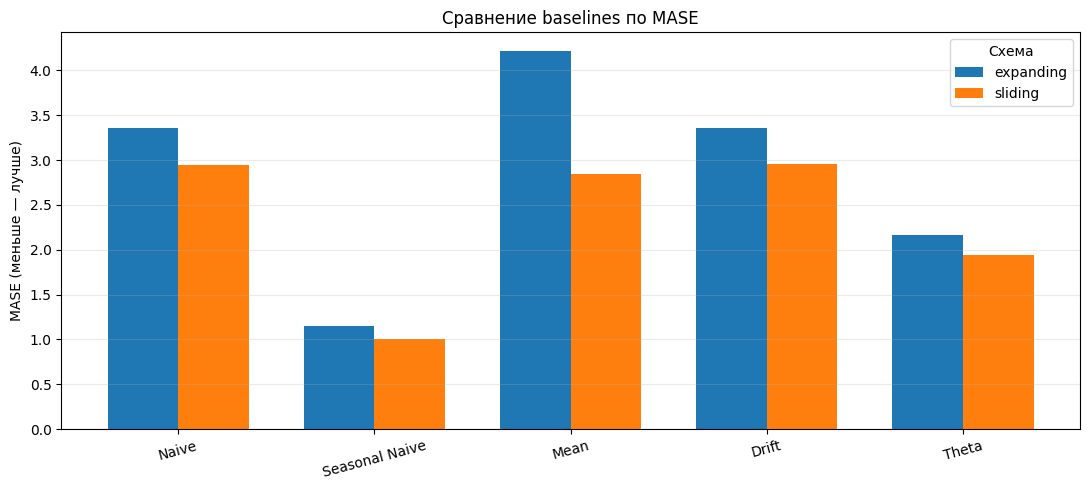

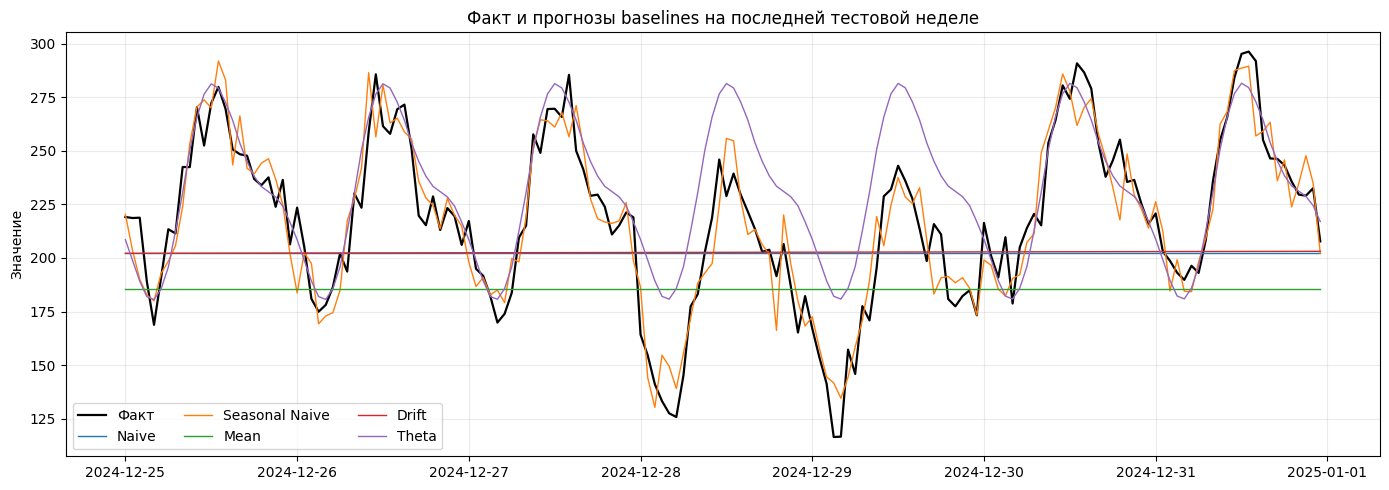

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
models = list(BASELINES.keys())
x = np.arange(len(models))
width = 0.36
for k, scheme in enumerate(["expanding", "sliding"]):
    vals = [metrics_summary.loc[(metrics_summary["Схема"] == scheme) & (metrics_summary["Модель"] == m), "MASE (s=168)"].iloc[0] for m in models]
    ax.bar(x + (k - 0.5) * width, vals, width, label=scheme)
ax.set_xticks(x, models, rotation=15)
ax.set_ylabel("MASE (меньше — лучше)")
ax.set_title("Сравнение baselines по MASE")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Схема")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_baseline_mase.png", dpi=150, bbox_inches="tight")
plt.show()

# Сопоставление прогнозов всех baselines на одном и том же недельном блоке.
last_start = fold_starts[-1]
last_test_index = series.iloc[last_start:last_start + HORIZON].index
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(last_test_index, series.iloc[last_start:last_start + HORIZON].to_numpy(), label="Факт", linewidth=1.6, color="black")
for model_name in BASELINES:
    pred = forecast_store[("expanding", N_SPLITS, model_name)]["prediction"]
    ax.plot(last_test_index, pred, label=model_name, linewidth=1)
ax.set_title("Факт и прогнозы baselines на последней тестовой неделе")
ax.set_ylabel("Значение")
ax.grid(alpha=0.25)
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_baseline_forecasts_last_week.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Обоснование выбора метрик с точки зрения стоимости ошибок

В синтетическом наборе нет заданной денежной или операционной функции потерь. Поэтому по одним значениям метрик нельзя утверждать, что какая-либо из них является единственно правильной для реального бизнеса. Выбор зависит от того, как организация оценивает недопрогноз и перепрогноз.

Для данного ряда **MAE можно принять основной метрикой при условии симметричной линейной стоимости ошибок**: отклонения на 10 единиц вверх и вниз считаются одинаково дорогими. MAE сохраняет единицы исходного ряда и показывает средний размер абсолютной ошибки. **RMSE** следует приводить дополнительно, если крупные промахи особенно нежелательны: квадратичное штрафование сильнее увеличивает вклад редких больших ошибок. **MASE** нужен для сравнения качества относительно сезонного наивного ориентира и не зависит от масштаба измерения ряда. **Bias** показывает направление систематической ошибки и дополняет MAE.

| Условие задачи | Метрика для оценки |
|---|---|
| Недопрогноз и перепрогноз имеют одинаковую линейную стоимость | MAE |
| Крупные ошибки обходятся непропорционально дорого | RMSE вместе с MAE |
| Нужно сравнить ряды разных масштабов или проверить выигрыш относительно сезонного ориентира | MASE |
| Важно обнаруживать систематическое завышение или занижение | Bias вместе с MAE |
| Недопрогноз и перепрогноз имеют разную стоимость | Асимметричная функция потерь или Quantile/Pinball Loss |

В рассматриваемом эксперименте у ряда есть одно нулевое фактическое значение в тестовых блоках. Поэтому MAPE рассчитан только по ненулевым фактам: число точек для него меньше общего числа тестовых наблюдений. Это ограничение отражено в столбце `MAPE points total`; MAPE не следует использовать здесь как единственную метрику.

По полученным результатам Seasonal Naive занимает первое место среди пяти проверенных baselines по MAE, RMSE и MASE. Однако его MASE остаётся выше 1 в обеих схемах. Следовательно, он является **лучшим из сравниваемых вариантов**, но не превосходит по тестовой ошибке сезонный наивный ориентир, рассчитанный на обучающем отрезке, это различие важно при интерпретации результата.

## 9. Интервальный прогноз Seasonal Naive

Для интервала используется эмпирическое распределение ошибок Seasonal Naive. Первые шесть expanding-фолдов служат калибровочными, последние четыре — независимой проверкой покрытия. Квантили остатков 2,5% и 97,5% дают номинальный 95%-й интервал. Для неотрицательного ряда нижняя граница ограничивается нулём.

Покрытие и ширина интервала оцениваются по каждому часу $h=1,...,H$ и дополнительно агрегируются по 24-часовым участкам. По каждому отдельному часу число проверочных фолдов невелико, поэтому почасовая оценка coverage имеет высокую выборочную неопределённость.

Калибровочные фолды: [1, 2, 3, 4, 5, 6]; проверочные фолды: [7, 8, 9, 10]
Калибровочные квантили остатков: q2.5%=-27.142, q97.5%=29.210
Coverage по 24-часовым участкам:


,"Горизонт, ч",Width,N,"Coverage, %"
0,1–24,56.353,96,97.917
1,25–48,56.353,96,92.708
2,49–72,56.353,96,96.875
3,73–96,56.353,96,96.875
4,97–120,56.353,96,92.708
5,121–144,56.353,96,96.875
6,145–168,56.353,96,94.792


Coverage и width для каждого часа горизонта h=1,...,H. На каждый h приходится число проверочных фолдов, указанное в Validation_folds:


,"Горизонт h, ч",Width,Validation_folds,"Coverage, %"
0,1,56.353,4,100.0
1,2,56.353,4,100.0
2,3,56.353,4,100.0
3,4,56.353,4,100.0
4,5,56.353,4,100.0
...,...,...,...,...
163,164,56.353,4,100.0
164,165,56.353,4,100.0
165,166,56.353,4,75.0
166,167,56.353,4,100.0


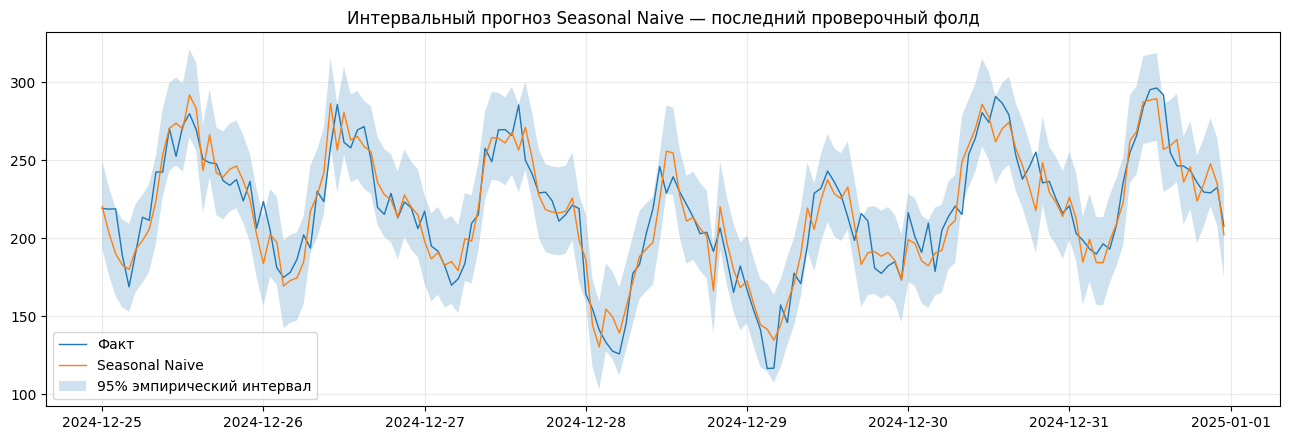

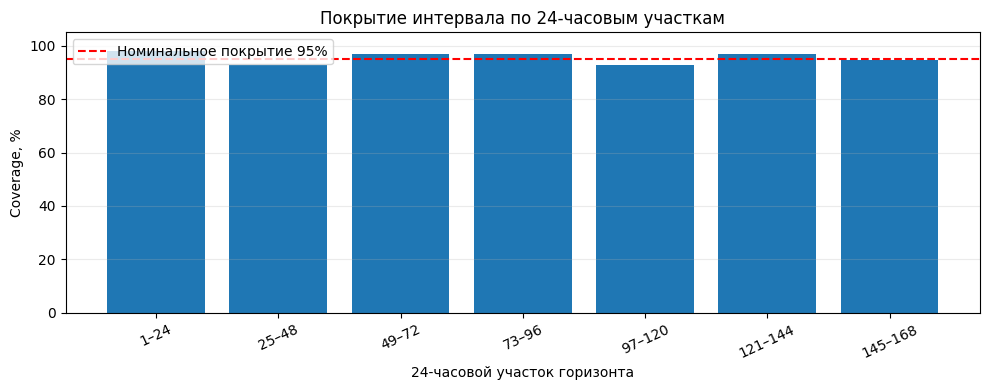

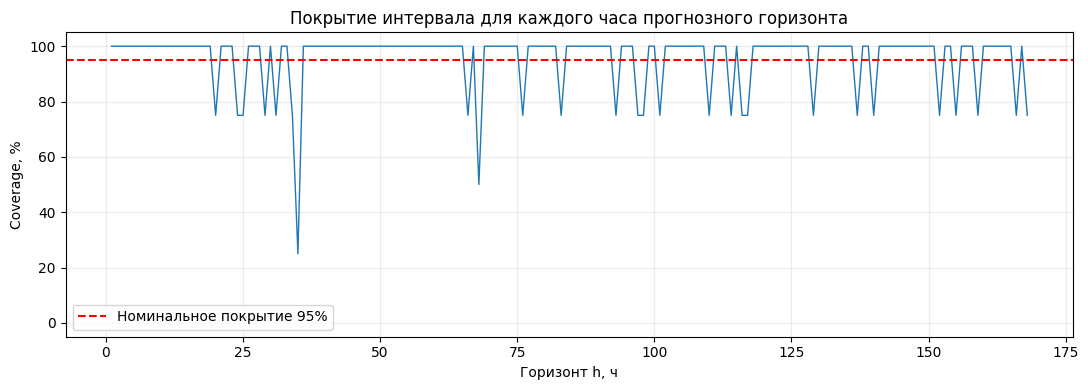

In [9]:
# Первые 60% фолдов используются для калибровки, оставшиеся — для проверки.
# При N_SPLITS=10 это 6 калибровочных и 4 проверочных фолда.
n_calibration = max(1, min(N_SPLITS - 1, int(np.floor(0.60 * N_SPLITS))))
calibration_folds = range(1, n_calibration + 1)
validation_folds = range(n_calibration + 1, N_SPLITS + 1)

calibration_errors = []
for fold_id in calibration_folds:
    item = forecast_store[("expanding", fold_id, "Seasonal Naive")]
    calibration_errors.extend((item["test"].to_numpy() - item["prediction"]).tolist())

q_low, q_high = np.quantile(np.asarray(calibration_errors), [0.025, 0.975])
interval_rows = []
hourly_interval_rows = []
interval_plot_data = None

for fold_id in validation_folds:
    item = forecast_store[("expanding", fold_id, "Seasonal Naive")]
    actual = item["test"].to_numpy()
    prediction = item["prediction"]
    lower = np.maximum(0.0, prediction + q_low)
    upper = np.maximum(lower, prediction + q_high)
    covered = (actual >= lower) & (actual <= upper)
    widths = upper - lower
    interval_plot_data = (item["test"].index, actual, prediction, lower, upper)

    # Детализация по каждому часу горизонта h=1,...,H.
    for h in range(HORIZON):
        hourly_interval_rows.append({
            "Fold": fold_id,
            "Горизонт h, ч": h + 1,
            "Coverage": int(covered[h]),
            "Width": float(widths[h]),
        })

    # Дополнительная сводка по 24-часовым участкам для более наглядного графика.
    for bin_start in range(0, HORIZON, 24):
        bin_end = min(bin_start + 24, HORIZON)
        sl = slice(bin_start, bin_end)
        interval_rows.append({
            "Fold": fold_id,
            "Горизонт, ч": f"{bin_start + 1}–{bin_end}",
            "Coverage": float(covered[sl].mean()),
            "Width": float(widths[sl].mean()),
            "Число точек": int(bin_end - bin_start),
        })

interval_results = pd.DataFrame(interval_rows)
interval_summary = interval_results.groupby("Горизонт, ч", sort=False).agg(
    Coverage=("Coverage", "mean"),
    Width=("Width", "mean"),
    N=("Число точек", "sum"),
).reset_index()
interval_summary["Coverage, %"] = interval_summary.pop("Coverage") * 100

hourly_interval_results = pd.DataFrame(hourly_interval_rows)
hourly_interval_summary = hourly_interval_results.groupby("Горизонт h, ч", sort=True).agg(
    Coverage=("Coverage", "mean"),
    Width=("Width", "mean"),
    Validation_folds=("Fold", "nunique"),
).reset_index()
hourly_interval_summary["Coverage, %"] = hourly_interval_summary.pop("Coverage") * 100

print(f"Калибровочные фолды: {list(calibration_folds)}; проверочные фолды: {list(validation_folds)}")
print(f"Калибровочные квантили остатков: q2.5%={q_low:.3f}, q97.5%={q_high:.3f}")
print("Coverage по 24-часовым участкам:")
display(interval_summary.round(3))
print("Coverage и width для каждого часа горизонта h=1,...,H. На каждый h приходится число проверочных фолдов, указанное в Validation_folds:")
display(hourly_interval_summary.round(3))

idx, actual, prediction, lower, upper = interval_plot_data
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(idx, actual, label="Факт", linewidth=1)
ax.plot(idx, prediction, label="Seasonal Naive", linewidth=1)
ax.fill_between(idx, lower, upper, alpha=0.22, label="95% эмпирический интервал")
ax.set_title("Интервальный прогноз Seasonal Naive — последний проверочный фолд")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_seasonal_naive_interval.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(interval_summary["Горизонт, ч"], interval_summary["Coverage, %"])
ax.axhline(95, color="red", linestyle="--", label="Номинальное покрытие 95%")
ax.set_ylim(0, 105)
ax.set_ylabel("Coverage, %")
ax.set_xlabel("24-часовой участок горизонта")
ax.set_title("Покрытие интервала по 24-часовым участкам")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_interval_coverage_24h_blocks.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hourly_interval_summary["Горизонт h, ч"], hourly_interval_summary["Coverage, %"], linewidth=1)
ax.axhline(95, color="red", linestyle="--", label="Номинальное покрытие 95%")
ax.set_ylim(-5, 105)
ax.set_xlabel("Горизонт h, ч")
ax.set_ylabel("Coverage, %")
ax.set_title("Покрытие интервала для каждого часа прогнозного горизонта")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_interval_coverage_by_horizon.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Демонстрация утечки при случайном разбиении

Для демонстрации используется Random Forest с лагами и скользящими средними. Все лаговые признаки рассчитываются только из предыдущих фактических значений. Тем не менее, если случайно перемешать строки, в обучающую выборку могут попасть более поздние даты, а признаки таких строк могут включать фактические значения из тестового периода.

Сначала выполняется обычное сравнение случайного 80/20-разбиения и хронологического 80/20-разбиения. У этих вариантов **разные тестовые наблюдения**, поэтому их MAE иллюстрируют риск утечки, но не дают парной оценки её величины.

Затем проводится дополнительная проверка на **одном и том же непрерывном тестовом интервале** в середине ряда. Сравниваются два обучающих набора одинакового размера:

- хронологический — только наблюдения до начала тестового интервала;
- перемешанный — случайная выборка из наблюдений до и после тестового интервала.

В обоих вариантах прогноз оценивается на одних и тех же датах, а размер обучения одинаков. Во втором варианте обучающие данные содержат будущие относительно теста наблюдения; кроме того, лаговые признаки первых строк после тестового блока могут включать фактические значения из самого тестового блока. Это и есть недопустимая для реального прогноза информация.

Контроль с одинаковым тестом делает сравнение более сопоставимым, но не превращает результат в универсальную оценку смещения: обучающие наборы отличаются не только временным порядком, но и составом дат. Полученный эффект относится к данному синтетическому ряду, набору признаков и параметрам Random Forest.

In [10]:
# Признаки строятся только из прошлых значений ряда.
leakage_data = pd.DataFrame({"y": series})
for lag in [1, 24, 168]:
    leakage_data[f"lag_{lag}"] = series.shift(lag)
leakage_data["rolling_mean_24"] = series.shift(1).rolling(24).mean()
leakage_data["rolling_mean_168"] = series.shift(1).rolling(168).mean()
leakage_data["hour"] = series.index.hour
leakage_data["day_of_week"] = series.index.dayofweek
leakage_data = leakage_data.dropna()
X = leakage_data.drop(columns="y")
y_target = leakage_data["y"]

rf_params = {
    "n_estimators": 120,
    "min_samples_leaf": 2,
    "max_features": 0.9,
    "random_state": SEED,
    "n_jobs": -1,
}

leakage_rows = []

# Эксперимент 1. Стандартное случайное и хронологическое разбиение 80/20.
X_rand_train, X_rand_test, y_rand_train, y_rand_test = train_test_split(
    X, y_target, test_size=0.20, random_state=SEED, shuffle=True
)
random_forest_random = RandomForestRegressor(**rf_params)
random_forest_random.fit(X_rand_train, y_rand_train)
pred_random = random_forest_random.predict(X_rand_test)

split_point = int(len(X) * 0.80)
X_chron_train, X_chron_test = X.iloc[:split_point], X.iloc[split_point:]
y_chron_train, y_chron_test = y_target.iloc[:split_point], y_target.iloc[split_point:]
random_forest_chron = RandomForestRegressor(**rf_params)
random_forest_chron.fit(X_chron_train, y_chron_train)
pred_chron = random_forest_chron.predict(X_chron_test)

# Для случайного split считаем, у какой доли тестовых дат в train есть более поздние даты.
random_train_dates = X_rand_train.index
random_test_dates = X_rand_test.index
future_train_share = float(np.mean([
    np.any(random_train_dates > test_date) for test_date in random_test_dates
]) * 100)

leakage_rows.extend([
    {
        "Эксперимент": "Стандартное разбиение 80/20 (разные тесты)",
        "Схема": "Случайное разбиение",
        "MAE": mean_absolute_error(y_rand_test, pred_random),
        "RMSE": np.sqrt(mean_squared_error(y_rand_test, pred_random)),
        "Размер train": len(y_rand_train),
        "Размер test": len(y_rand_test),
        "Тестовые даты с более поздними train-наблюдениями, %": future_train_share,
        "Train после тестового блока, %": np.nan,
    },
    {
        "Эксперимент": "Стандартное разбиение 80/20 (разные тесты)",
        "Схема": "Хронологическое разбиение",
        "MAE": mean_absolute_error(y_chron_test, pred_chron),
        "RMSE": np.sqrt(mean_squared_error(y_chron_test, pred_chron)),
        "Размер train": len(y_chron_train),
        "Размер test": len(y_chron_test),
        "Тестовые даты с более поздними train-наблюдениями, %": 0.0,
        "Train после тестового блока, %": 0.0,
    },
])

# Эксперимент 2. Фиксируем один и тот же непрерывный тестовый блок для обеих схем.
# Тест занимает 20% наблюдений, начиная с 60% временной оси.
n_rows = len(X)
paired_test_size = int(np.floor(0.20 * n_rows))
paired_test_start = int(np.floor(0.60 * n_rows))
paired_test_end = paired_test_start + paired_test_size
if paired_test_end >= n_rows:
    raise ValueError("Недостаточно данных после фиксированного тестового блока.")

X_paired_test = X.iloc[paired_test_start:paired_test_end]
y_paired_test = y_target.iloc[paired_test_start:paired_test_end]

# В корректном варианте обучаемся только на прошлом.
X_paired_chron_train = X.iloc[:paired_test_start]
y_paired_chron_train = y_target.iloc[:paired_test_start]

# В демонстрационно некорректном варианте берём столько же строк,
# но случайно из всех дат вне тестового блока, включая будущие относительно теста.
available_positions = np.r_[0:paired_test_start, paired_test_end:n_rows]
if len(available_positions) < len(X_paired_chron_train):
    raise ValueError("Недостаточно доступных строк для matched-size случайного обучения.")
paired_rng = np.random.default_rng(SEED)
paired_random_positions = np.sort(paired_rng.choice(
    available_positions, size=len(X_paired_chron_train), replace=False
))
X_paired_random_train = X.iloc[paired_random_positions]
y_paired_random_train = y_target.iloc[paired_random_positions]

paired_chron_model = RandomForestRegressor(**rf_params)
paired_chron_model.fit(X_paired_chron_train, y_paired_chron_train)
pred_paired_chron = paired_chron_model.predict(X_paired_test)

paired_random_model = RandomForestRegressor(**rf_params)
paired_random_model.fit(X_paired_random_train, y_paired_random_train)
pred_paired_random = paired_random_model.predict(X_paired_test)

# Доля перемешанных обучающих строк, дата которых находится после всего тестового блока.
paired_future_train_share = float(np.mean(
    X_paired_random_train.index > X_paired_test.index[-1]
) * 100)

leakage_rows.extend([
    {
        "Эксперимент": "Одинаковый фиксированный тестовый блок",
        "Схема": "Хронологическое обучение",
        "MAE": mean_absolute_error(y_paired_test, pred_paired_chron),
        "RMSE": np.sqrt(mean_squared_error(y_paired_test, pred_paired_chron)),
        "Размер train": len(y_paired_chron_train),
        "Размер test": len(y_paired_test),
        "Тестовые даты с более поздними train-наблюдениями, %": 0.0,
        "Train после тестового блока, %": 0.0,
    },
    {
        "Эксперимент": "Одинаковый фиксированный тестовый блок",
        "Схема": "Перемешанное обучение с будущими данными",
        "MAE": mean_absolute_error(y_paired_test, pred_paired_random),
        "RMSE": np.sqrt(mean_squared_error(y_paired_test, pred_paired_random)),
        "Размер train": len(y_paired_random_train),
        "Размер test": len(y_paired_test),
        "Тестовые даты с более поздними train-наблюдениями, %": 100.0 if paired_future_train_share > 0 else 0.0,
        "Train после тестового блока, %": paired_future_train_share,
    },
])

leakage_results = pd.DataFrame(leakage_rows)
display(leakage_results.round(4))

# Значения для формулирования итогового вывода.
standard_random_mae = float(leakage_results.iloc[0]["MAE"])
standard_chron_mae = float(leakage_results.iloc[1]["MAE"])
paired_chron_mae = float(leakage_results.iloc[2]["MAE"])
paired_random_mae = float(leakage_results.iloc[3]["MAE"])
paired_mae_change = (paired_chron_mae - paired_random_mae) / paired_chron_mae * 100 if paired_chron_mae > 0 else np.nan

print(
    f"Обычный split: MAE случайного = {standard_random_mae:.2f}; "
    f"MAE хронологического = {standard_chron_mae:.2f}. Тестовые множества различаются."
)
print(
    f"Один и тот же тестовый блок ({X_paired_test.index[0]} — {X_paired_test.index[-1]}): "
    f"MAE хронологического обучения = {paired_chron_mae:.2f}; "
    f"MAE перемешанного обучения = {paired_random_mae:.2f}."
)
print(
    f"Размер train в парном эксперименте одинаков ({len(X_paired_chron_train)} строк); "
    f"доля обучающих дат после тестового блока в перемешанном варианте = {paired_future_train_share:.1f}%."
)
print(
    f"MAE перемешанного обучения ниже на {paired_mae_change:.1f}% относительно "
    "хронологического варианта на этом фиксированном тесте."
)

,Эксперимент,Схема,MAE,RMSE,Размер train,Размер test,"Тестовые даты с более поздними train-наблюдениями, %","Train после тестового блока, %"
0,Стандартное разбиение 80/20 (разные тесты),Случайное разбиение,8.0868,11.0721,13900,3476,100.0,NaN
1,Стандартное разбиение 80/20 (разные тесты),Хронологическое разбиение,9.7126,13.8202,13900,3476,0.0,0.0000
2,Одинаковый фиксированный тестовый блок,Хронологическое обучение,9.6520,12.9681,10425,3475,0.0,0.0000
3,Одинаковый фиксированный тестовый блок,Перемешанное обучение с будущими данными,8.9317,12.1301,10425,3475,100.0,24.9976


Обычный split: MAE случайного = 8.09; MAE хронологического = 9.71. Тестовые множества различаются.
Один и тот же тестовый блок (2024-03-17 09:00:00 — 2024-08-09 03:00:00): MAE хронологического обучения = 9.65; MAE перемешанного обучения = 8.93.
Размер train в парном эксперименте одинаков (10425 строк); доля обучающих дат после тестового блока в перемешанном варианте = 25.0%.
MAE перемешанного обучения ниже на 7.5% относительно хронологического варианта на этом фиксированном тесте.


## 11. Выводы

In [11]:
best_exp = metrics_summary.loc[metrics_summary["Схема"] == "expanding"].sort_values("MASE (s=168)").iloc[0]
best_slid = metrics_summary.loc[metrics_summary["Схема"] == "sliding"].sort_values("MASE (s=168)").iloc[0]
mean_std_by_scheme = stability_summary.groupby("Схема")["Стандартное_отклонение_MAE"].mean()
more_stable_scheme = mean_std_by_scheme.idxmin()

std_by_model = stability_summary.pivot(
    index="Модель", columns="Схема", values="Стандартное_отклонение_MAE"
)
expanding_lower_count = int((std_by_model["expanding"] < std_by_model["sliding"] - 1e-12).sum())
equal_std_count = int(np.isclose(std_by_model["expanding"], std_by_model["sliding"]).sum())

ranking_rows = []
for scheme in ["expanding", "sliding"]:
    part = metrics_summary.loc[metrics_summary["Схема"] == scheme]
    ranking_rows.append({
        "Схема": scheme,
        "Лучшая по MAE": part.loc[part["MAE"].idxmin(), "Модель"],
        "Лучшая по RMSE": part.loc[part["RMSE"].idxmin(), "Модель"],
        "Лучшая по MASE": part.loc[part["MASE (s=168)"].idxmin(), "Модель"],
    })
ranking_table = pd.DataFrame(ranking_rows)
display(ranking_table)

,Схема,Лучшая по MAE,Лучшая по RMSE,Лучшая по MASE
0,expanding,Seasonal Naive,Seasonal Naive,Seasonal Naive
1,sliding,Seasonal Naive,Seasonal Naive,Seasonal Naive


1. В обеих схемах лучший baseline по MASE это Seasonal Naive. Для expanding MAE = 11.33, RMSE = 15.55, MASE = 1.146. Для sliding MAE = 11.33, RMSE = 15.55, MASE = 1.006. Победитель по MAE, RMSE и MASE совпадает в обеих схемах.

2. MASE выше 1 в обеих схемах. Поэтому лидерство среди проверенных кандидатов не означает автоматического превосходства над сезонным ориентиром на обучающем отрезке.

3. По среднему стандартному отклонению MAE между фолдами expanding стабильнее: 1.314 против 1.420. Для 3 из 5 моделей SD ниже у expanding, ещё у 2 моделей значения совпадают.

4. Для Seasonal Naive стандартное отклонение MAE одинаково в expanding и sliding (0.8284), а прогнозы совпадают. Обе схемы используют одну и ту же последнюю неделю перед каждым общим тестовым блоком.

5. Интервал Seasonal Naive имеет фактическое покрытие 95.5% и среднюю ширину 56.35. Для каждого отдельного часа горизонта доступно только 4 проверочных фолда, поэтому почасовое покрытие имеет высокую выборочную неопределённость.

6. В обычном сравнении split MAE случайного разбиения = 8.09, хронологического = 9.71, но тестовые множества различаются. В дополнительном сравнении на одинаковом тестовом блоке MAE хронологического обучения = 9.65, перемешанного обучения = 8.93. Размеры train и теста одинаковы (10425 и 3475 наблюдений), 25.0% перемешанных обучающих наблюдений датированы позже тестового блока. MAE перемешанного варианта ниже на 7.5%, что демонстрирует риск утечки на данном ряду, но не является универсальной оценкой завышения качества.

7. MAE выбран как основная метрика только при предположении о симметричной линейной стоимости ошибок. RMSE дополняет его при высокой цене крупных промахов, MASE сравнивает модели с сезонным наивным ориентиром, Bias показывает направление смещения. Для асимметричной стоимости недопрогноза и перепрогноза нужна соответствующая функция потерь.

8. MAPE усреднён по ненулевым фактическим значениям. В этом эксперименте использовано 1679 точек из 1680, поскольку нулевое фактическое значение делает MAPE неопределённым.

9. Корректная схема валидации. Для оценки моделей используется последовательный backtesting на последних 10 недельных блоках с горизонтом 168 часов. В Expanding Window обучение включает все наблюдения до начала тестового блока, а в Sliding Window — последние 672 часа. Обе схемы используют одинаковые тестовые интервалы, что обеспечивает корректность сравнения. На каждом шаге модель обучается только на прошлых данных.

## 12. Сохранение результатов

В папку `results_lecture4_baselines/` экспортируются исходный ряд, сводные метрики по моделям и схемам, метрики отдельных фолдов, интервальное покрытие и результаты диагностики утечки. Графики сохраняются в PNG.

In [12]:
series.rename("cnt").to_frame().to_csv(OUTPUT_DIR / "synthetic_hourly_series.csv", index_label="timestamp")
metrics_summary.to_csv(OUTPUT_DIR / "baseline_metrics_summary.csv", index=False)
fold_results.to_csv(OUTPUT_DIR / "backtesting_fold_metrics.csv", index=False)
interval_summary.to_csv(OUTPUT_DIR / "interval_coverage_width_24h_blocks.csv", index=False)
hourly_interval_summary.to_csv(OUTPUT_DIR / "interval_coverage_by_horizon.csv", index=False)
leakage_results.to_csv(OUTPUT_DIR / "random_split_leakage_diagnostic.csv", index=False)
stability_summary.to_csv(OUTPUT_DIR / "backtesting_stability.csv", index=False)

last_fold = N_SPLITS
last_test = forecast_store[("expanding", last_fold, "Seasonal Naive")]["test"]
forecast_export = pd.DataFrame({"actual": last_test.to_numpy()}, index=last_test.index)
for model_name in BASELINES:
    forecast_export[model_name] = forecast_store[("expanding", last_fold, model_name)]["prediction"]
forecast_export.to_csv(OUTPUT_DIR / "last_fold_forecasts.csv", index_label="timestamp")

print("Сохранены файлы:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Сохранены файлы:
- 01_series.png
- 02_last_week.png
- 03_baseline_mase.png
- 04_baseline_forecasts_last_week.png
- 05_seasonal_naive_interval.png
- 06_interval_coverage_24h_blocks.png
- 07_interval_coverage_by_horizon.png
- backtesting_fold_metrics.csv
- backtesting_stability.csv
- baseline_metrics_summary.csv
- interval_coverage_by_horizon.csv
- interval_coverage_width_24h_blocks.csv
- last_fold_forecasts.csv
- random_split_leakage_diagnostic.csv
- synthetic_hourly_series.csv
